<a href="https://colab.research.google.com/github/tanu100/DeepLearning/blob/main/ArtificalNeuralNetwork/Optimizers_in_DL/Adam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Adam Optimizer

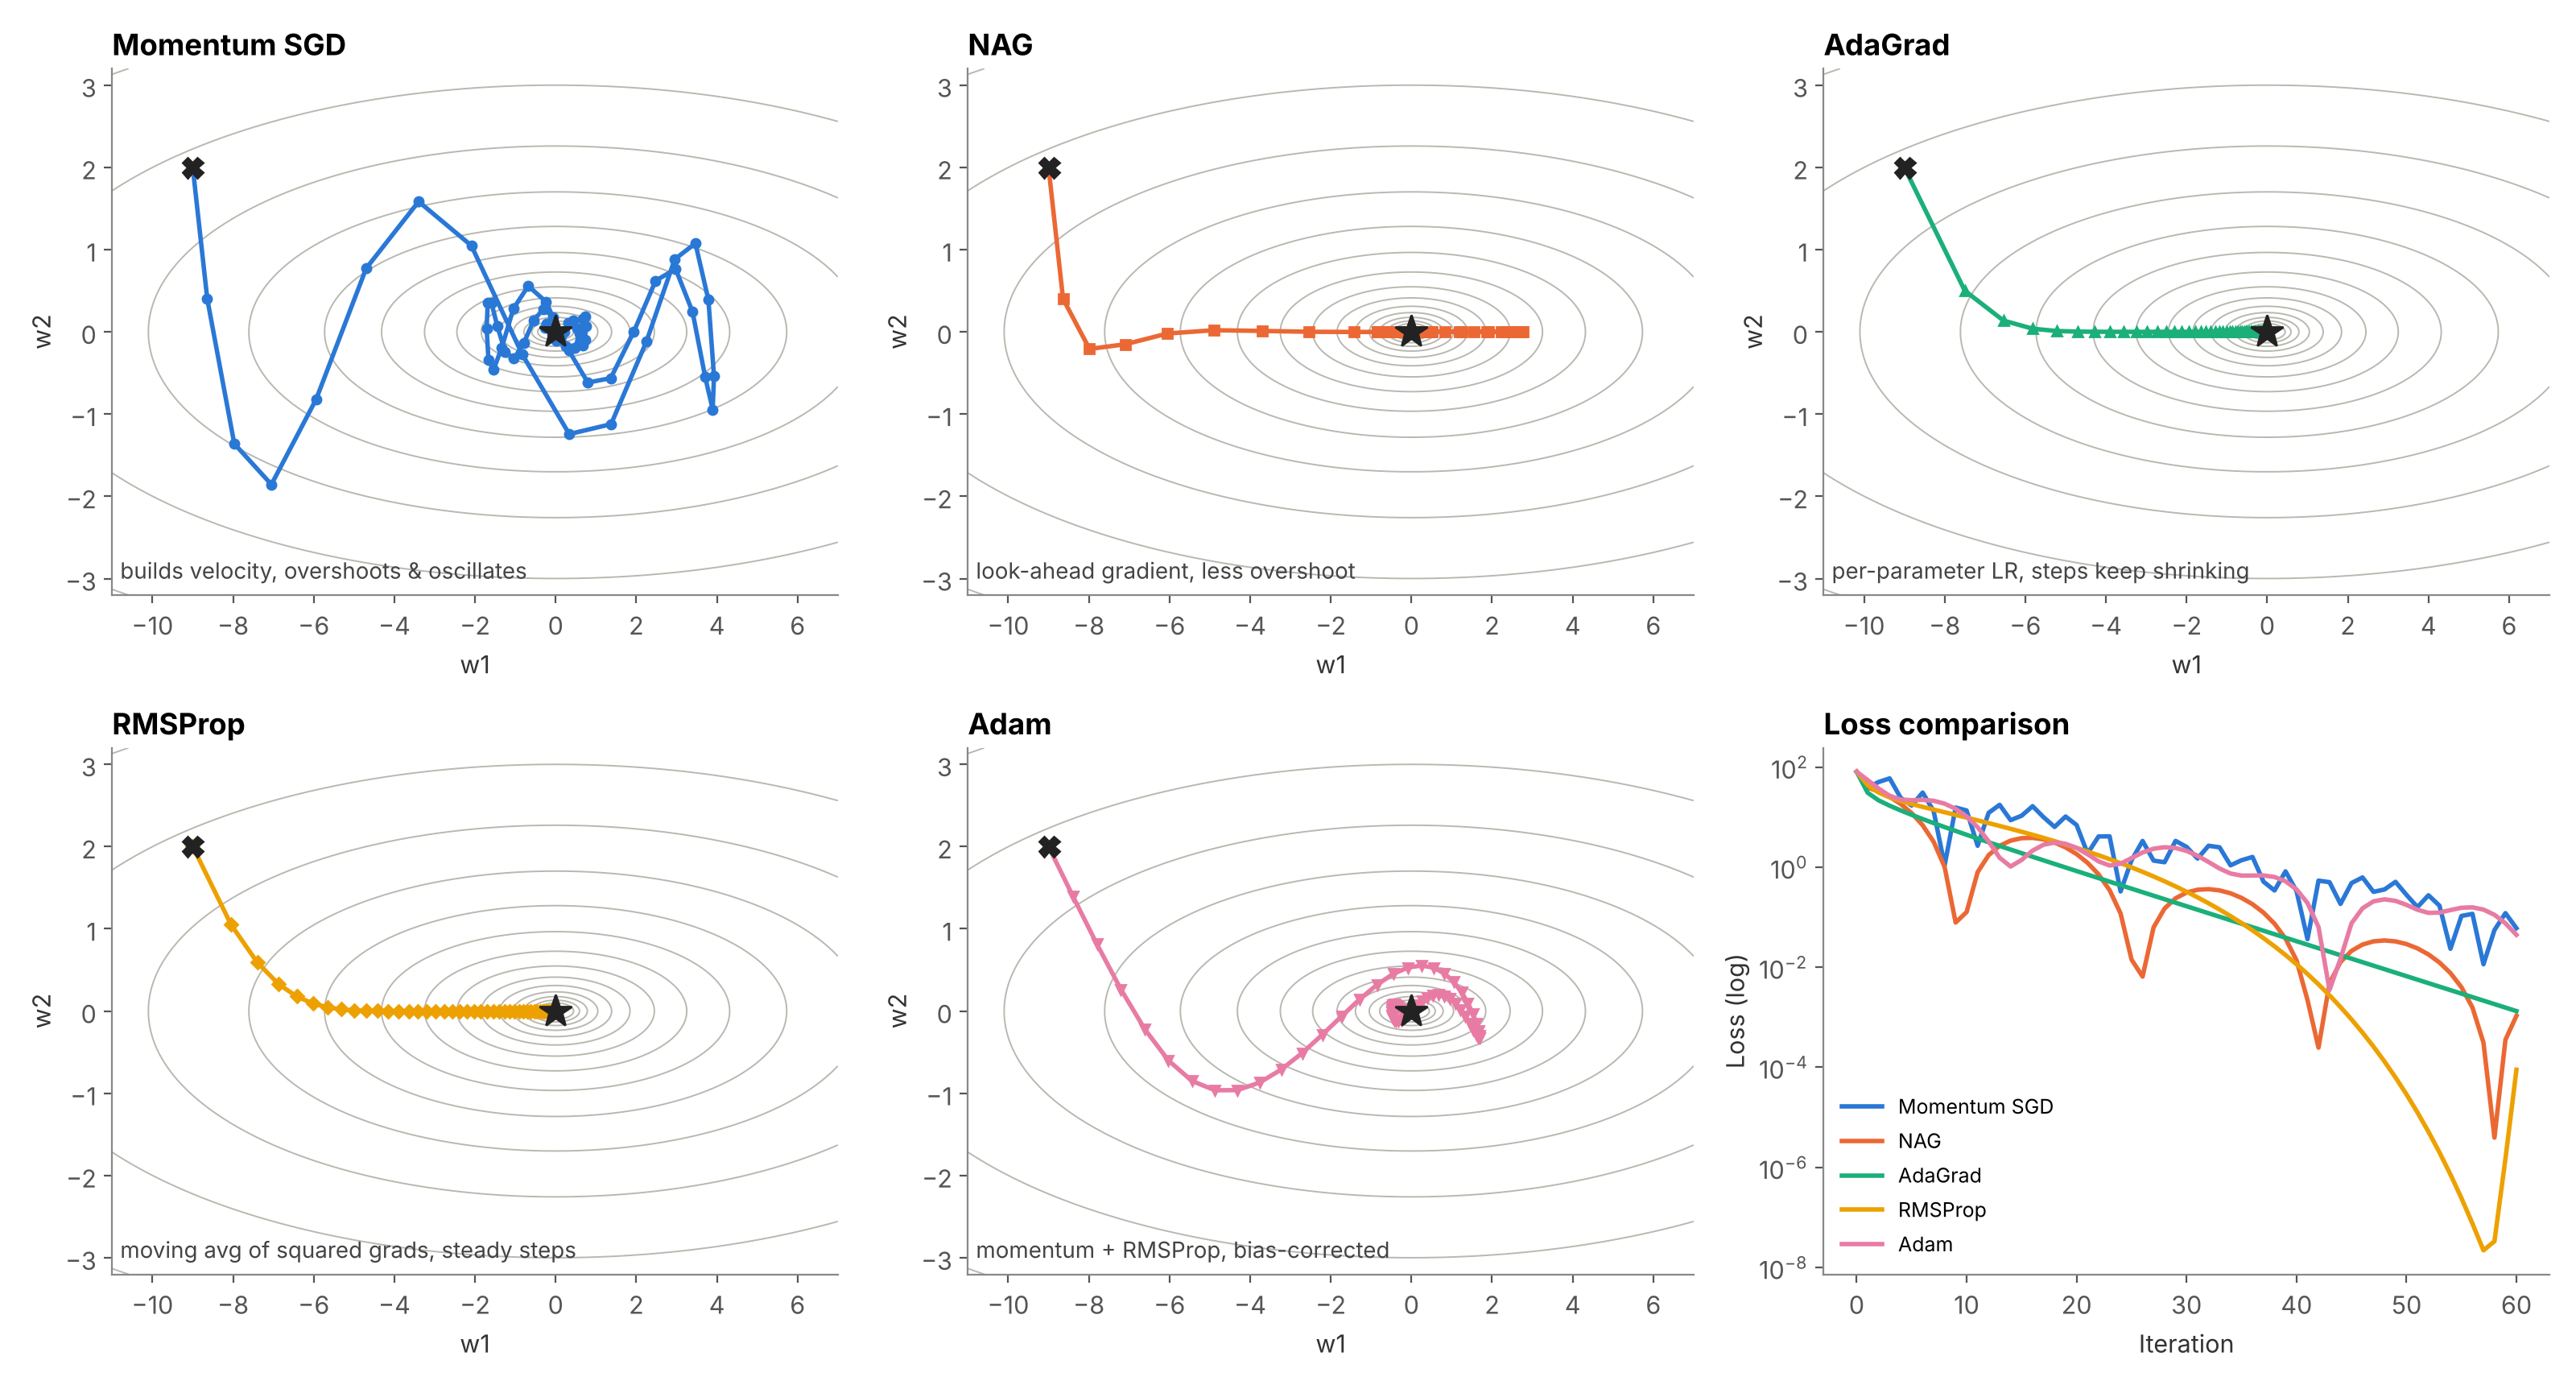

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

In [2]:
from sklearn.datasets import make_regression

x,y=make_regression(n_features=3,n_samples=10000,n_targets=1,noise=0.2,random_state=42)

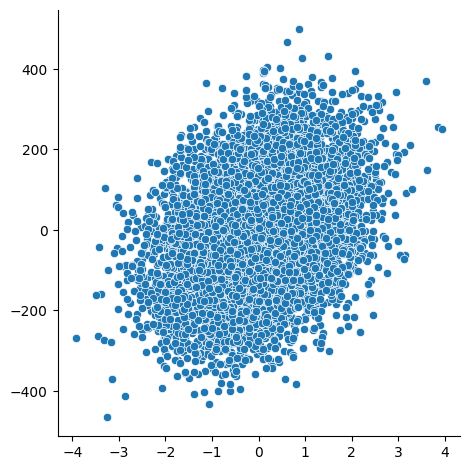

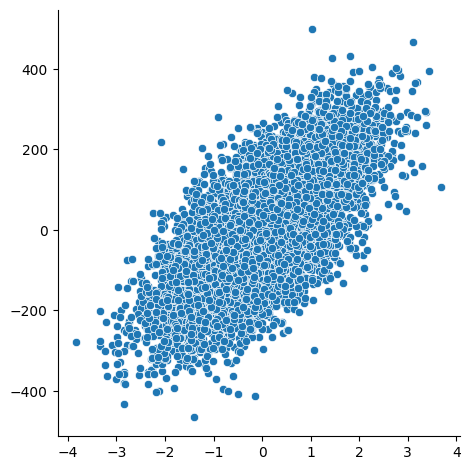

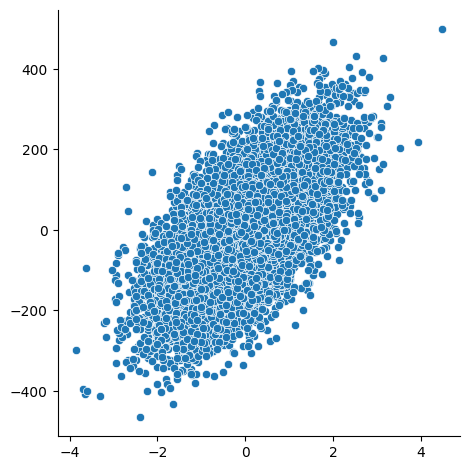

In [3]:
sns.relplot(x=x[:, 0], y=y, kind='scatter')
sns.relplot(x=x[:, 1], y=y, kind='scatter')
sns.relplot(x=x[:, 2], y=y, kind='scatter')

In [9]:
class Adam:

    def __init__(self, m=None, c=0, lr=1, epochs=100,beta1=0.9,beta2=0.99):
        self.m = m
        self.c = c
        self.lr = lr
        self.epoch = epochs
        self.beta1=beta1
        self.beta2=beta2
        self.past_dc = 0.0
        self.moment_dc=0.0
        self.past_dm = None
        self.moment_dm=None
        self.epsilon = 1e-8

    def fit(self, x, y):

        self.m = np.zeros(x.shape[1])
        self.c = 0.0

        self.past_dc = 0.0
        self.moment_dc=0.0
        self.past_dm = np.zeros(x.shape[1])
        self.moment_dm=np.zeros(x.shape[1])

        t=0
        for _ in range(self.epoch):

            for i in range(x.shape[0]):

                x_i = x[i]
                y_i = y[i]

                y_hat = self.c + (x_i @ self.m)

                # Calculate gradients
                dc = 2 * (y_hat - y_i)
                dm = 2 * (y_hat - y_i) * x_i

                t+=1

                #Calculating the Momentum for m and c
                #m(t) = beta1 * m(t-1) + (1 - beta2) * gradient(t)

                self.moment_dm= self.beta1 * self.moment_dm + (1 - self.beta2) * dm
                self.moment_dc= self.beta1 * self.moment_dc + (1 - self.beta2) * dc

                #Calculating the Past Squared Gradients for m and c
                #v(t) = beta1 * v(t-1) + (1 - beta2) * gradient(t)

                self.past_dm=self.beta1 * self.past_dm + (1 - self.beta2) * dm**2
                self.past_dc=self.beta1 * self.past_dc + (1 - self.beta2) * dc**2


                #Bias Correction for moment of m and c
                # m_parameter_hat = momentum_parameter / 1 - beta1 ** no_of_iterations

                m_m_hat=self.moment_dm / (1 - self.beta1 ** t)
                m_c_hat=self.moment_dc / (1 - self.beta1 ** t)

                #Bias Correction for gradient of m and c
                # v_parameter_hat = pastSquaredGradients_parameter / 1 - beta2 ** no_of_iterations

                v_m_hat=self.past_dm / (1 - self.beta2 ** t)
                v_c_hat=self.past_dc / (1 - self.beta2 ** t)

                # Update bias
                # paramter(t + 1) = parameter(t) - (learning_rate * m_parameter_hat)/(v_parameter_hat + epsilon)**0.5

                self.c -= (
                    self.lr * m_c_hat /
                    (np.sqrt(v_c_hat) + self.epsilon)
                )

                # Update weights
                self.m -= (
                    self.lr * m_m_hat /
                    (np.sqrt(v_m_hat) + self.epsilon)
                )

    def predict(self, x_test):
        return x_test @ self.m + self.c

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.3,
    random_state=42
)

print(X_train.shape)  # (7000, 3)
print(X_test.shape)   # (3000, 3)

(7000, 3)
(3000, 3)


In [11]:
adam = Adam(
    lr=0.01,
    epochs=50
)

adam.fit(X_train, y_train)

y_pred = adam.predict(X_test)

In [12]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Adam MSE:", mse)
print("Adam R2 Score:", r2)

print("Weights:", adam.m)
print("Bias:", adam.c)

Adam MSE: 0.03988851363575344
Adam R2 Score: 0.9999975398739778
Weights: [43.33687414 88.17938682 83.17500163]
Bias: 0.022771044871928183


In [13]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Sklearn weights:", model.coef_)
print("Sklearn bias:", model.intercept_)
print("Sklearn MSE:", mean_squared_error(y_test, model.predict(X_test)))
print("Sklearn R2:", r2_score(y_test, model.predict(X_test)))

Sklearn weights: [43.32492571 88.16711621 83.18805164]
Sklearn bias: 0.0013884060104775164
Sklearn MSE: 0.038690120819693384
Sklearn R2: 0.999997613784913
